# Bad Debt Modeling

Run the cells from top to bottom. Cleaning and EDA are in their own notebooks. We split the original data first and balance only the training data. Bad = 1; Good = 0.

## 1. Import Libraries

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.utils import resample
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay
import joblib

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
SAMPLING_METHOD = "oversampling"  # Or "undersampling"

## 2. Load the Given Dataset

In [2]:
data = pd.read_csv(ROOT / "data/processed/dataset_SFM_Selected.csv")
# A missing outcome cannot be used as a training label.
data = data[data["OUTCOME"].isin(["Good", "Bad"])].copy()
X = data.drop(columns=["OUTCOME", "Customer", "OUTCOME_ENC"], errors="ignore").select_dtypes(include="number")
X = X.replace([np.inf, -np.inf], np.nan)
y = data["OUTCOME"].map({"Good": 0, "Bad": 1})
print(data["OUTCOME"].value_counts())

OUTCOME
Good    84341
Bad      7481
Name: count, dtype: int64


## 3. Split into Training and Test Data

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 68866
Test rows: 22956


## 4. Fill Missing Feature Values

Learn the medians from training data, then use those medians for both sets.

In [4]:
imputer = SimpleImputer(strategy="median", keep_empty_features=True)
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test = pd.DataFrame(imputer.transform(X_test), columns=X.columns, index=X_test.index)

## 5. Balance Only the Training Data

Oversampling repeats minority-class rows. Undersampling keeps fewer majority-class rows. The test set is not resampled.

In [5]:
train = X_train.copy()
train["OUTCOME_ENC"] = y_train
print("Before sampling:")
print(train["OUTCOME_ENC"].value_counts())

if SAMPLING_METHOD == "oversampling":
    target_size = train["OUTCOME_ENC"].value_counts().max()
elif SAMPLING_METHOD == "undersampling":
    target_size = train["OUTCOME_ENC"].value_counts().min()
else:
    raise ValueError("Use oversampling or undersampling")

balanced_parts = []
for label in [0, 1]:
    group = train[train["OUTCOME_ENC"] == label]
    if len(group) < target_size:
        # Keep every original row and add randomly repeated rows.
        extra = resample(group, replace=True, n_samples=target_size - len(group), random_state=42)
        group = pd.concat([group, extra])
    elif len(group) > target_size:
        group = resample(group, replace=False, n_samples=target_size, random_state=42)
    balanced_parts.append(group)

train = pd.concat(balanced_parts).sample(frac=1, random_state=42).reset_index(drop=True)
X_train = train.drop(columns="OUTCOME_ENC")
y_train = train["OUTCOME_ENC"]
print("After sampling:")
print(y_train.value_counts())

Before sampling:
OUTCOME_ENC
0    63255
1     5611
Name: count, dtype: int64


After sampling:
OUTCOME_ENC
1    63255
0    63255
Name: count, dtype: int64


## 6. Train Random Forest and View Feature Importance

Top 10 features:
SCORE_CR22                 0.251294
RISK_SCORE                 0.167828
NO_ADDRESS_AT_MONTHS       0.099066
EMPLOYED_NO_MTHS           0.083933
NO_SCORE                   0.082211
NO_SCORE_CR21              0.064526
RISK_RELATIVE_ODDS_CR21    0.063772
RISK_RELATIVE_CR21         0.056568
NO_SUM_VCR053              0.048230
NO_MONTHS_VCR228           0.033056
dtype: float64
Lowest 10 features:
NO_ADDRESS_AT_MONTHS       0.099066
EMPLOYED_NO_MTHS           0.083933
NO_SCORE                   0.082211
NO_SCORE_CR21              0.064526
RISK_RELATIVE_ODDS_CR21    0.063772
RISK_RELATIVE_CR21         0.056568
NO_SUM_VCR053              0.048230
NO_MONTHS_VCR228           0.033056
ENQUIRIES_12M              0.027437
ENQUIRIES_6M               0.022080
dtype: float64


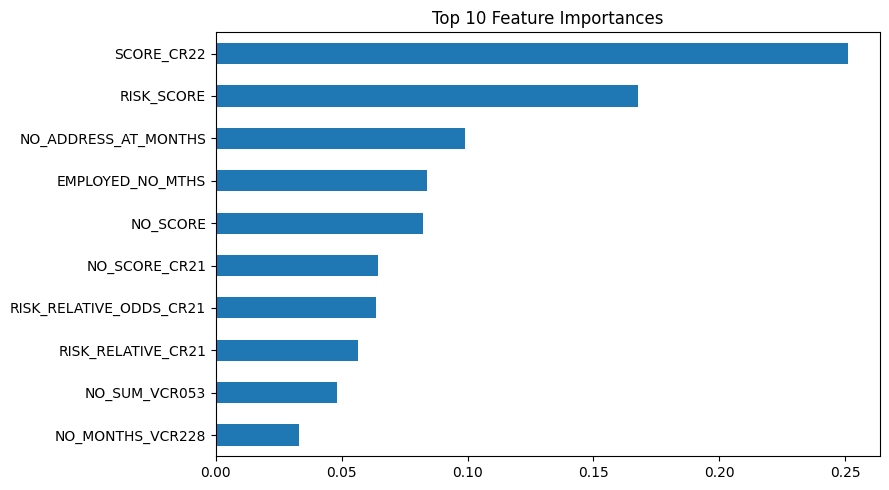

In [6]:
rf = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Top 10 features:")
print(importance.head(10))
print("Lowest 10 features:")
print(importance.tail(10))
importance.head(10).sort_values().plot.barh(figsize=(9, 5), title="Top 10 Feature Importances")
plt.tight_layout()
plt.show()

## 7. Compare Models and Feature Groups

Every model uses the same balanced training rows and original test rows. Logistic regression scales features using training data.

In [7]:
feature_sets = {
    "Credit Scores": [c for c in ["RISK_SCORE", "NO_SCORE", "SCORE_CR22"] if c in X.columns],
    "Risk Features": [c for c in X.columns if "RISK_" in c and c != "RISK_RELATIVE_CR21"],
    "Selected Features": X.columns.tolist(),
    "SFM Selected": X.columns.tolist(),
    "Risk Relative Index": [c for c in ["RISK_RELATIVE_CR21"] if c in X.columns],
    "Credit + Risk": [c for c in ["RISK_SCORE", "NO_SCORE", "SCORE_CR22", "RISK_RELATIVE_CR21"] if c in X.columns],
}
results = []
trained_models = {}
for set_name, columns in feature_sets.items():
    if not columns:
        continue
    models = {
        "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42)),
        "Random Forest": RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1),
        "HistGradientBoosting": HistGradientBoostingClassifier(random_state=42),
    }
    for model_name, model in models.items():
        model.fit(X_train[columns], y_train)
        prediction = model.predict(X_test[columns])
        probability = model.predict_proba(X_test[columns])[:, 1]
        report = classification_report(y_test, prediction, output_dict=True, zero_division=0)
        results.append({
            "Feature Set": set_name, "Model": model_name,
            "AUC": roc_auc_score(y_test, probability),
            "Accuracy": report["accuracy"],
            "Bad Recall": report["1"]["recall"],
            "Bad F1": report["1"]["f1-score"],
        })
        trained_models[(set_name, model_name)] = model
result_df = pd.DataFrame(results).sort_values("AUC", ascending=False).reset_index(drop=True)
print(result_df.to_string(index=False))

        Feature Set                Model      AUC  Accuracy  Bad Recall   Bad F1
       SFM Selected HistGradientBoosting 0.754402  0.722338    0.625668 0.268533
  Selected Features HistGradientBoosting 0.754402  0.722338    0.625668 0.268533
      Credit Scores HistGradientBoosting 0.748540  0.707266    0.638503 0.262187
      Credit + Risk HistGradientBoosting 0.747589  0.709357    0.632086 0.261620
  Selected Features  Logistic Regression 0.743964  0.670631    0.671658 0.249380
       SFM Selected  Logistic Regression 0.743964  0.670631    0.671658 0.249380
      Credit + Risk  Logistic Regression 0.743347  0.665491    0.674332 0.247231
      Credit Scores  Logistic Regression 0.742733  0.649939    0.685561 0.241887
      Risk Features HistGradientBoosting 0.741281  0.689101    0.642781 0.251965
      Risk Features  Logistic Regression 0.731044  0.596184    0.720856 0.225305
Risk Relative Index HistGradientBoosting 0.706824  0.699120    0.576471 0.237890
       SFM Selected        R

## 8. Evaluate the Best Model

AUC measures how well the model ranks Bad versus Good applicants. Bad recall and F1 help assess minority-class predictions.

Best model: HistGradientBoosting on SFM Selected


              precision    recall  f1-score   support

        Good       0.96      0.73      0.83     21086
         Bad       0.17      0.63      0.27      1870

    accuracy                           0.72     22956
   macro avg       0.56      0.68      0.55     22956
weighted avg       0.89      0.72      0.78     22956

Confusion matrix (Good, Bad):


[[15412  5674]
 [  700  1170]]


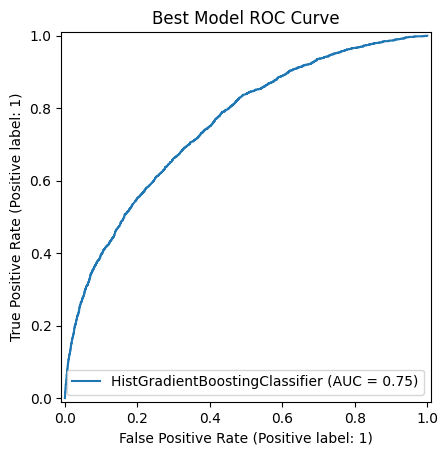

In [8]:
best = result_df.iloc[0]
best_model = trained_models[(best["Feature Set"], best["Model"])]
best_columns = feature_sets[best["Feature Set"]]
best_X_test = X_test[best_columns]
print("Best model:", best["Model"], "on", best["Feature Set"])
print(classification_report(y_test, best_model.predict(best_X_test), target_names=["Good", "Bad"], zero_division=0))
print("Confusion matrix (Good, Bad):")
print(confusion_matrix(y_test, best_model.predict(best_X_test)))
RocCurveDisplay.from_estimator(best_model, best_X_test, y_test)
plt.title("Best Model ROC Curve")
plt.show()

## 9. Explain Predictions with SHAP

Use a small sample to keep this step quick. Positive contributions increase the predicted probability of Bad debt.

C:\Users\Sakthi Jayakumar\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



PermutationExplainer explainer:   5%|▌         | 1/20 [00:00<?, ?it/s]


PermutationExplainer explainer:  25%|██▌       | 5/20 [00:37<00:00, 25.99it/s]


PermutationExplainer explainer:  40%|████      | 8/20 [00:37<00:00, 18.29it/s]


PermutationExplainer explainer:  50%|█████     | 10/20 [00:37<00:00, 17.92it/s]


PermutationExplainer explainer:  60%|██████    | 12/20 [00:37<00:00, 18.30it/s]


PermutationExplainer explainer:  75%|███████▌  | 15/20 [00:37<00:00, 20.12it/s]


PermutationExplainer explainer:  90%|█████████ | 18/20 [00:37<00:00, 18.29it/s]


PermutationExplainer explainer: 100%|██████████| 20/20 [00:38<00:00, 17.89it/s]


PermutationExplainer explainer: 21it [00:38,  1.90s/it]                        

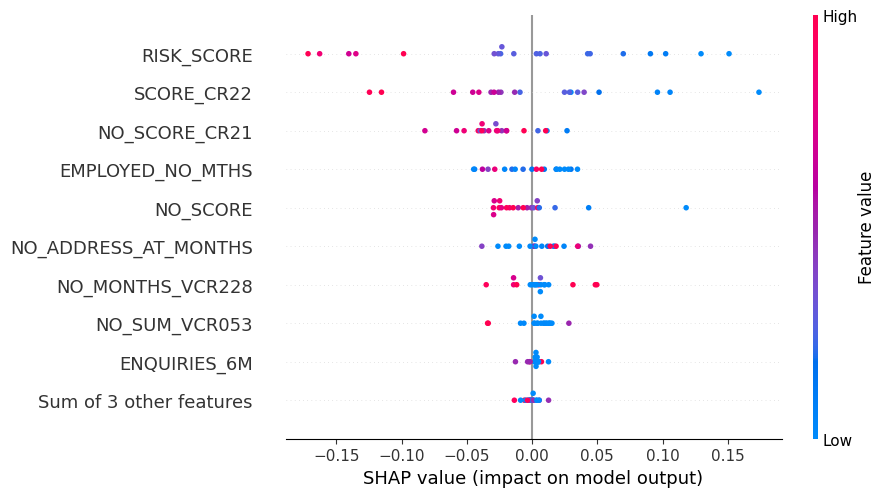

In [9]:
import shap
background = X_train[best_columns].sample(n=min(30, len(X_train)), random_state=42)
examples = best_X_test.sample(n=min(20, len(best_X_test)), random_state=42)

def predict_bad(values):
    frame = pd.DataFrame(values, columns=best_columns)
    return best_model.predict_proba(frame)[:, 1]

explainer = shap.Explainer(predict_bad, background, algorithm="permutation", seed=42)
shap_values = explainer(examples, max_evals=2 * len(best_columns) + 1)
shap.plots.beeswarm(shap_values)

## 10. Save Results and Datasets

In [10]:
(ROOT / "results").mkdir(exist_ok=True)
(ROOT / "models").mkdir(exist_ok=True)
result_df.to_csv(ROOT / "results/model_comparison_results.csv", index=False)
joblib.dump({"model": best_model, "imputer": imputer, "input_columns": X.columns.tolist(),
             "model_columns": best_columns, "target_mapping": {"Good": 0, "Bad": 1}},
            ROOT / "models/best_model.joblib")
joblib.dump(trained_models, ROOT / "models/trained_models.joblib")
train_export = X_train.copy()
train_export["OUTCOME"] = y_train.map({0: "Good", 1: "Bad"})
train_export.to_csv(ROOT / f"data/processed/dataset_SFM_Selected_train_{SAMPLING_METHOD}.csv", index=False)
test_export = X_test.copy()
test_export["OUTCOME"] = y_test.map({0: "Good", 1: "Bad"})
test_export.to_csv(ROOT / "data/processed/dataset_SFM_Selected_test.csv", index=False)
print("Saved model results, models, balanced training data, and test data.")

Saved model results, models, balanced training data, and test data.
